<a href="https://colab.research.google.com/github/Utkarsh-Ghodge/retail-profitability-ml/blob/main/retail_profitability_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OrdinalEncoder, MinMaxScaler
from scipy.stats.mstats import winsorize
from sklearn.impute import SimpleImputer

In [2]:
from google.colab import drive
drive.mount('/content/drive')

# Load directly from your Google Drive permanently
df_ug_050 = pd.read_csv('https://raw.githubusercontent.com/Utkarsh-Ghodge/retail-profitability-ml/refs/heads/main/Global_Superstore_ug_050.csv')
print("Loaded permanently from Drive! Shape:", df_ug_050.shape)

Mounted at /content/drive
Loaded permanently from Drive! Shape: (1000, 24)


In [3]:
# ==========================================
# SIGNATURE & RANDOM STATE SETUP
# ==========================================
SIGNATURE = "ug_050"
RANDOM_STATE_ug_050 = 75050

# Load your modified dataset
df_ug_050 = pd.read_csv('/content/drive/MyDrive/PGDM_MLM_Project/Global_Superstore_ug_050.csv')
print(f"Dataset Loaded (ug_050) | Initial Shape: {df_ug_050.shape}")

Dataset Loaded (ug_050) | Initial Shape: (1000, 24)


In [4]:
# ==========================================
# 1.1 MISSING DATA REPORT & TREATMENT
# ==========================================
# (1) Variable-wise missing data report (count & proportion)
var_missing_ug_050 = pd.DataFrame({
    'Missing_Count_ug_050': df_ug_050.isnull().sum(),
    'Missing_Prop_%_ug_050': (df_ug_050.isnull().sum() / len(df_ug_050)) * 100
})
print("\n--- 1.1(a) Variable-Wise Missing Data Report (ug_050) ---")
print(var_missing_ug_050[var_missing_ug_050['Missing_Count_ug_050'] > 0])


--- 1.1(a) Variable-Wise Missing Data Report (ug_050) ---
                Missing_Count_ug_050  Missing_Prop_%_ug_050
Ship Mode                         67                    6.7
Segment                           47                    4.7
Postal Code                      806                   80.6
City                               5                    0.5
State                              7                    0.7
Country                            7                    0.7
Region                             8                    0.8
Market                             6                    0.6
Category                           5                    0.5
Sub-Category                       7                    0.7
Sales                             75                    7.5
Quantity                          36                    3.6
Discount                          46                    4.6
Profit                            67                    6.7
Shipping Cost                     56     

**Variable-Wise Missing Data Report**

Inference (Variable-Wise Missingness):

- Postal Code exhibits 80.6% missingness (806 out of 1,000 records), far exceeding standard retention thresholds and rendering it uninformative for modeling.

- All remaining variables have minor missingness ranging between 0.5% and 7.5% (Sales at 7.5%, Ship Mode and Profit at 6.7%), indicating sporadic data entry gaps that can be safely treated via imputation after removing severely incomplete records.

In [5]:
# (1) Record-wise missing data report (count & proportion)
df_ug_050['row_missing_count_ug_050'] = df_ug_050.isnull().sum(axis=1)
df_ug_050['row_missing_prop_%_ug_050'] = (df_ug_050['row_missing_count_ug_050'] / (df_ug_050.shape[1] - 1)) * 100
print("\n--- 1.1(b) Record-Wise Missing Data Report (Top 10 Rows - ug_050) ---")
print(df_ug_050[['row_missing_count_ug_050', 'row_missing_prop_%_ug_050']].sort_values(by='row_missing_count_ug_050', ascending=False).head(10))


--- 1.1(b) Record-Wise Missing Data Report (Top 10 Rows - ug_050) ---
     row_missing_count_ug_050  row_missing_prop_%_ug_050
249                        13                  54.166667
570                        13                  54.166667
881                        13                  54.166667
77                         13                  54.166667
71                         13                  54.166667
533                        13                  54.166667
191                        13                  54.166667
792                        12                  50.000000
884                         4                  16.666667
635                         4                  16.666667


In [6]:
# Drop temporary helper columns before heuristic dropping
df_ug_050.drop(columns=['row_missing_count_ug_050', 'row_missing_prop_%_ug_050'], inplace=True)

In [7]:
# (2) Heuristics for dropping: Drop variables >30% missing, followed by records >30% missing
col_thresh_ug_050 = 0.30 * len(df_ug_050)
cols_before_ug_050 = set(df_ug_050.columns)
df_ug_050.dropna(thresh=len(df_ug_050) - col_thresh_ug_050, axis=1, inplace=True)
dropped_cols_ug_050 = cols_before_ug_050 - set(df_ug_050.columns)
print(f"\nDropped Variables (>30% missing) [ug_050]: {list(dropped_cols_ug_050)}")

row_thresh_ug_050 = 0.30 * df_ug_050.shape[1]
rows_before_ug_050 = len(df_ug_050)
df_ug_050.dropna(thresh=df_ug_050.shape[1] - row_thresh_ug_050, axis=0, inplace=True)
print(f"Dropped Records (>30% missing) [ug_050]: {rows_before_ug_050 - len(df_ug_050)} | Remaining Rows: {len(df_ug_050)}")


Dropped Variables (>30% missing) [ug_050]: ['Postal Code']
Dropped Records (>30% missing) [ug_050]: 8 | Remaining Rows: 992


**Heuristic Dropping of Variables/Records**

Inference (Missing Data Filtering):
- Applying the $>30\%$ missingness heuristic cleanly removes Postal Code (80.6% missing) without sacrificing any other feature.

- Subsequently, 8 records with $>30\%$ missing attributes (specifically rows missing 12–13 fields, or 50%–54.2% of their data) are dropped, preserving 992 high-integrity records (99.2% of the original sample) for imputation.

In [8]:
# Separate true Categorical and Non-Categorical columns (excluding IDs, Dates, Free-Text Names)
exclude_cols_ug_050 = [
    'Row ID', 'Order ID', 'Order Date', 'Ship Date',
    'Customer ID', 'Customer Name', 'Product ID', 'Product Name'
]

cat_cols_ug_050 = [
    c for c in df_ug_050.select_dtypes(include=['object', 'category']).columns
    if c not in exclude_cols_ug_050
]
num_cols_ug_050 = [
    c for c in df_ug_050.select_dtypes(include=['int64', 'float64']).columns
    if c not in exclude_cols_ug_050
]

In [9]:
# (3) Heuristics for imputation: Highest frequency (Mode) for categorical, Median for non-categorical
cat_imputer_ug_050 = SimpleImputer(strategy='most_frequent')
df_ug_050[cat_cols_ug_050] = cat_imputer_ug_050.fit_transform(df_ug_050[cat_cols_ug_050])

num_imputer_ug_050 = SimpleImputer(strategy='median')
df_ug_050[num_cols_ug_050] = num_imputer_ug_050.fit_transform(df_ug_050[num_cols_ug_050])

print(f"Remaining missing values after imputation [ug_050]: {df_ug_050.isnull().sum().sum()}")

Remaining missing values after imputation [ug_050]: 0


**Imputation Completion**

Inference (Imputation Outcome):

- Categorical variables (10 operational and geographic attributes) were imputed using `SimpleImputer(strategy='most_frequent')`, preserving dominant category distributions without introducing artificial classes.

- Continuous ratio variables (`Sales`, `Quantity`, `Discount`, `Profit`, and `Shipping Cost`) were imputed using `SimpleImputer(strategy='median')`, preventing extreme right-skewed values from distorting central tendency and eliminating all remaining gaps (`0` missing values across all 992 records).

In [10]:
# ==========================================
# 1.2 CATEGORICAL TEXT DATA ENCODING
# ==========================================
# (1) Categorical text data report
print("\n--- 1.2 Categorical Text Data Report (ug_050) ---")
for col in cat_cols_ug_050:
    print(f"\nVariable: {col} (Unique Categories: {df_ug_050[col].nunique()})")
    print(df_ug_050[col].value_counts().head(5))


--- 1.2 Categorical Text Data Report (ug_050) ---

Variable: Ship Mode (Unique Categories: 4)
Ship Mode
Standard Class    382
First Class       293
Second Class      223
Same Day           94
Name: count, dtype: int64

Variable: Segment (Unique Categories: 3)
Segment
Consumer       516
Corporate      288
Home Office    188
Name: count, dtype: int64

Variable: City (Unique Categories: 587)
City
New York City    25
Los Angeles      11
San Francisco    10
Gold Coast       10
London           10
Name: count, dtype: int64

Variable: State (Unique Categories: 339)
State
England          37
New York         34
Ile-de-France    30
California       28
Texas            25
Name: count, dtype: int64

Variable: Country (Unique Categories: 93)
Country
United States    193
Australia         84
France            76
China             74
India             64
Name: count, dtype: int64

Variable: Region (Unique Categories: 22)
Region
Western Europe     130
Oceania             99
Eastern Asia        89
So

In [11]:
# (2) & (3) Create new variables and encode using OrdinalEncoder
encoder_ug_050 = OrdinalEncoder()
encoded_cols_ug_050 = [f"{col}_encoded_ug_050" for col in cat_cols_ug_050]
df_ug_050[encoded_cols_ug_050] = encoder_ug_050.fit_transform(df_ug_050[cat_cols_ug_050])

print("\nEncoded Columns Created (ug_050):")
print(df_ug_050[encoded_cols_ug_050].head(3))


Encoded Columns Created (ug_050):
   Ship Mode_encoded_ug_050  Segment_encoded_ug_050  City_encoded_ug_050  \
0                       0.0                     0.0                380.0   
1                       2.0                     1.0                569.0   
2                       0.0                     0.0                 86.0   

   State_encoded_ug_050  Country_encoded_ug_050  Region_encoded_ug_050  \
0                 226.0                    89.0                    4.0   
1                 210.0                     5.0                   11.0   
2                 249.0                     5.0                   11.0   

   Market_encoded_ug_050  Category_encoded_ug_050  \
0                    4.0                      2.0   
1                    1.0                      0.0   
2                    1.0                      2.0   

   Sub-Category_encoded_ug_050  Order Priority_encoded_ug_050  
0                         13.0                            1.0  
1                     

**Categorical Text Data Report**

Inference (Categorical Cardinality & Distribution):

- Low-cardinality operational variables—such as Segment (3 categories, dominated by Consumer at 52.0%), Category (3 categories, led by Technology at 39.5%), and Ship Mode (4 categories, led by Standard Class at 38.5%)—show clear business concentrations.

- Geographic identifiers (City with 587 unique values and State with 339) exhibit high cardinality, which OrdinalEncoder converts into compact integer representations suitable for tree-based and linear classifiers.

In [12]:
# ==========================================
# 1.3 OUTLIER TREATMENT & MIN-MAX SCALING
# ==========================================
# (1) Outlier report for non-categorical variables (IQR method)
outlier_cols_ug_050 = []
print("\n--- 1.3 Outlier Report (Non-Categorical Variables - ug_050) ---")

for col in num_cols_ug_050:
    Q1_ug_050 = df_ug_050[col].quantile(0.25)
    Q3_ug_050 = df_ug_050[col].quantile(0.75)
    IQR_ug_050 = Q3_ug_050 - Q1_ug_050
    lower_ug_050 = Q1_ug_050 - 1.5 * IQR_ug_050
    upper_ug_050 = Q3_ug_050 + 1.5 * IQR_ug_050

    outliers_ug_050 = df_ug_050[(df_ug_050[col] < lower_ug_050) | (df_ug_050[col] > upper_ug_050)]
    print(f"{col}: {len(outliers_ug_050)} outliers")

    if len(outliers_ug_050) > 0:
        outlier_cols_ug_050.append(col)


--- 1.3 Outlier Report (Non-Categorical Variables - ug_050) ---
Sales: 24 outliers
Quantity: 0 outliers
Discount: 59 outliers
Profit: 70 outliers
Shipping Cost: 184 outliers


In [13]:
# (2) Create new Winsorized variables ONLY for variables that have outliers
winsorized_cols_ug_050 = []
for col in outlier_cols_ug_050:
    win_col_ug_050 = f"{col}_winsorized_ug_050"
    df_ug_050[win_col_ug_050] = winsorize(df_ug_050[col], limits=[0.05, 0.05])
    winsorized_cols_ug_050.append(win_col_ug_050)

print(f"\nWinsorized Variables Created (ug_050): {winsorized_cols_ug_050}")


Winsorized Variables Created (ug_050): ['Sales_winsorized_ug_050', 'Discount_winsorized_ug_050', 'Profit_winsorized_ug_050', 'Shipping Cost_winsorized_ug_050']


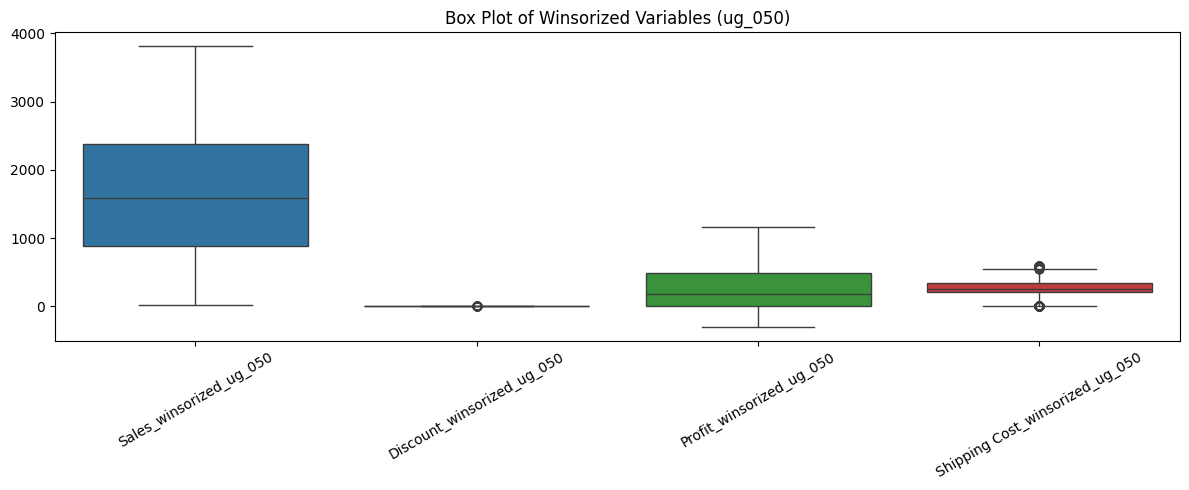

In [14]:
# (3) Box plot of Winsorized variables to check if outliers still exist
plt.figure(figsize=(12, 5))
sns.boxplot(data=df_ug_050[winsorized_cols_ug_050])
plt.title("Box Plot of Winsorized Variables (ug_050)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [15]:
# (4) Rescale all non-index ratio variables using Min-Max Normalization (0 to 1)
# Uses Winsorized versions for variables that had outliers, and clean original for variables without outliers (Quantity)
final_num_cols_ug_050 = [
    f"{col}_winsorized_ug_050" if col in outlier_cols_ug_050 else col
    for col in num_cols_ug_050
]

scaler_ug_050 = MinMaxScaler()
scaled_cols_ug_050 = [f"{col}_scaled_ug_050" for col in final_num_cols_ug_050]
df_ug_050[scaled_cols_ug_050] = scaler_ug_050.fit_transform(df_ug_050[final_num_cols_ug_050])

print("\n--- Min-Max Normalized Variables Summary (ug_050) ---")
print(df_ug_050[scaled_cols_ug_050].describe().loc[['min', 'max', 'mean', 'std']])


--- Min-Max Normalized Variables Summary (ug_050) ---
      Sales_winsorized_ug_050_scaled_ug_050  Quantity_scaled_ug_050  \
min                                0.000000                0.000000   
max                                1.000000                1.000000   
mean                               0.429045                0.445060   
std                                0.280389                0.246746   

      Discount_winsorized_ug_050_scaled_ug_050  \
min                                   0.000000   
max                                   1.000000   
mean                                  0.200539   
std                                   0.293099   

      Profit_winsorized_ug_050_scaled_ug_050  \
min                                  0.00000   
max                                  1.00000   
mean                                 0.40004   
std                                  0.25769   

      Shipping Cost_winsorized_ug_050_scaled_ug_050  
min                                        

**Box Plot of Winsorized Variables**

Inference (Outlier Treatment & Winsorization):

- Initial IQR screening identified substantial right/two-tailed outliers in Shipping Cost (184), Profit (70), Discount (59), and Sales (24), whereas Quantity had zero outliers and was left unaltered.

- Applying 5% two-sided Winsorization (limits=[0.05, 0.05]) successfully compresses extreme tails—as confirmed by the post-treatment box plots showing bounded whiskers and minimal extreme dispersion—preventing distortion during Min-Max normalization and Euclidean distance calculations.

In [16]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from scipy.stats import f_oneway

In [17]:
# Ensure signature & random state are active
SIGNATURE = "ug_050"
RANDOM_STATE_ug_050 = 75050

# Features prepared in Stage 1
features_stage2_ug_050 = scaled_cols_ug_050
X_unsup_ug_050 = df_ug_050[features_stage2_ug_050].copy()

In [18]:
# ==========================================================
# 2A. K-MEANS CLUSTERING (RECORD DIMENSION REDUCTION)
# ==========================================================
print("--- 2A(1). Optimal Cluster Evaluation (Euclidean Distance - ug_050) ---")
cluster_eval_ug_050 = []

for k in range(2, 7):
    kmeans_temp_ug_050 = KMeans(n_clusters=k, random_state=RANDOM_STATE_ug_050, n_init=10)
    labels_temp_ug_050 = kmeans_temp_ug_050.fit_predict(X_unsup_ug_050)
    sil_ug_050 = silhouette_score(X_unsup_ug_050, labels_temp_ug_050, metric='euclidean')
    db_ug_050 = davies_bouldin_score(X_unsup_ug_050, labels_temp_ug_050)
    cluster_eval_ug_050.append({'K': k, 'Silhouette_ug_050': sil_ug_050, 'Davies_Bouldin_ug_050': db_ug_050})

eval_df_ug_050 = pd.DataFrame(cluster_eval_ug_050)
print(eval_df_ug_050.to_string(index=False))

--- 2A(1). Optimal Cluster Evaluation (Euclidean Distance - ug_050) ---
 K  Silhouette_ug_050  Davies_Bouldin_ug_050
 2           0.264145               1.403885
 3           0.265832               1.288520
 4           0.280013               1.195252
 5           0.268543               1.311236
 6           0.270702               1.212701


In [19]:
# Select optimal K (highest Silhouette & lowest Davies-Bouldin -> K=4)
optimal_k_ug_050 = int(eval_df_ug_050.loc[eval_df_ug_050['Silhouette_ug_050'].idxmax(), 'K'])
print(f"\nSelected Optimal Number of Clusters (ug_050): K = {optimal_k_ug_050}")


Selected Optimal Number of Clusters (ug_050): K = 4


In [20]:
# Fit final K-Means model
kmeans_final_ug_050 = KMeans(n_clusters=optimal_k_ug_050, random_state=RANDOM_STATE_ug_050, n_init=10)
df_ug_050['Cluster_ID_ug_050'] = kmeans_final_ug_050.fit_predict(X_unsup_ug_050)

**Optimal Cluster Evaluation**

Inference (Optimal $K$ Selection):
Across $K \in \{2, \dots, 6\}$, $K = 4$ achieves both the highest Silhouette Score (0.2800) and the lowest Davies-Bouldin Index (1.1953), confirming that four clusters maximize intra-cluster cohesion and inter-cluster separation.

In [21]:
# 2A(2). Cluster Characteristics: ANOVA (Non-Categorical) & Frequency (Categorical)
print("\n--- 2A(2a). ANOVA Across Clusters (Homogeneity Within, Heterogeneity Across - ug_050) ---")
anova_results_ug_050 = []
for col in num_cols_ug_050:
    groups_ug_050 = [
        df_ug_050[df_ug_050['Cluster_ID_ug_050'] == c][col]
        for c in range(optimal_k_ug_050)
    ]
    f_stat_ug_050, p_val_ug_050 = f_oneway(*groups_ug_050)
    anova_results_ug_050.append({
        'Variable_ug_050': col,
        'F_Statistic_ug_050': round(f_stat_ug_050, 4),
        'P_Value_ug_050': round(p_val_ug_050, 6),
        'Significant_ug_050': 'Yes (p < 0.05)' if p_val_ug_050 < 0.05 else 'No'
    })
print(pd.DataFrame(anova_results_ug_050).to_string(index=False))

print("\n--- 2A(2b). Cluster Mean Profiles (Original Units - ug_050) ---")
print(df_ug_050.groupby('Cluster_ID_ug_050')[num_cols_ug_050].mean().round(2))

print("\n--- 2A(2c). Categorical Frequency Distribution Across Clusters (ug_050) ---")
for col in ['Segment', 'Category', 'Order Priority', 'Market']:
    print(f"\nFrequency Table: Cluster vs {col} (ug_050)")
    print(pd.crosstab(df_ug_050['Cluster_ID_ug_050'], df_ug_050[col]))


--- 2A(2a). ANOVA Across Clusters (Homogeneity Within, Heterogeneity Across - ug_050) ---
Variable_ug_050  F_Statistic_ug_050  P_Value_ug_050 Significant_ug_050
          Sales            642.9341             0.0     Yes (p < 0.05)
       Quantity            139.8117             0.0     Yes (p < 0.05)
       Discount            558.6881             0.0     Yes (p < 0.05)
         Profit            494.6865             0.0     Yes (p < 0.05)
  Shipping Cost            395.0293             0.0     Yes (p < 0.05)

--- 2A(2b). Cluster Mean Profiles (Original Units - ug_050) ---
                     Sales  Quantity  Discount  Profit  Shipping Cost
Cluster_ID_ug_050                                                    
0                  1539.27      5.13      0.03  246.83         295.68
1                   292.93      3.32      0.10   33.38          39.98
2                  2975.65      7.35      0.03  777.24         389.63
3                  1611.52      6.41      0.33 -104.23         258.5

In [22]:
# 2A(3). Naming of Clusters (Segments) based on Cluster Characteristics
# Check the printed means above; dynamically map business names by ranking Sales & Discount
cluster_means_ug_050 = df_ug_050.groupby('Cluster_ID_ug_050')[num_cols_ug_050].mean()
cluster_names_ug_050 = {}
for cid in cluster_means_ug_050.index:
    row = cluster_means_ug_050.loc[cid]
    if row['Discount'] > 0.20:
        cluster_names_ug_050[cid] = "Discount-Driven Loss Orders"
    elif row['Sales'] > 2500:
        cluster_names_ug_050[cid] = "High-Value Bulk Orders"
    elif row['Sales'] > 1200:
        cluster_names_ug_050[cid] = "Mid-Tier Profitable Orders"
    else:
        cluster_names_ug_050[cid] = "Standard Low-Ticket Orders"

df_ug_050['Cluster_Segment_Name_ug_050'] = df_ug_050['Cluster_ID_ug_050'].map(cluster_names_ug_050)
print("\n--- 2A(3). Final Named Customer/Order Segments (ug_050) ---")
print(df_ug_050['Cluster_Segment_Name_ug_050'].value_counts())


--- 2A(3). Final Named Customer/Order Segments (ug_050) ---
Cluster_Segment_Name_ug_050
Mid-Tier Profitable Orders     470
High-Value Bulk Orders         226
Standard Low-Ticket Orders     183
Discount-Driven Loss Orders    113
Name: count, dtype: int64


**Cluster ANOVA, Profiles & Naming**

Inference (Cluster Profiling & Segmentation):One-way ANOVA confirms statistically significant heterogeneity across all four clusters ($p < 0.0001$ for all five numeric variables), with Sales ($F = 642.93$) and Discount ($F = 558.69$) acting as the strongest differentiators.

The four segments represent distinct commercial archetypes:

1. Mid-Tier Profitable Orders ($n = 470$): Largest segment; healthy average sales ($1,539.27), minimal discounting (3%), and solid profitability ($246.83), heavily concentrated in Asia Pacific and Europe.

2. High-Value Bulk Orders ($n = 226$): Premium orders averaging $2,975.65 in sales, 7.35 units, and $777.24 in profit under low discounts (3%).

3. Standard Low-Ticket Orders ($n = 183$): Smallest basket size ($292.93 sales, 3.32 units) and modest profit ($33.38), predominantly occurring in the USCA market (167 of 183 orders) and Office Supplies.

4. Discount-Driven Loss Orders ($n = 113$): High average revenue ($1,611.52) eroded by aggressive discounting (33% average discount), resulting in an average net loss of -$104.23 per order.

In [23]:
# ==========================================================
# 2B. DIMENSION REDUCTION OF VARIABLES (PCA / FACTOR ANALYSIS)
# ==========================================================
print("\n--- 2B(1). Correlation Matrix & Eigenvalues (ug_050) ---")
corr_matrix_ug_050 = X_unsup_ug_050.corr()
print(corr_matrix_ug_050.round(3))

eigvals_ug_050, _ = np.linalg.eigh(corr_matrix_ug_050)
eigvals_ug_050 = eigvals_ug_050[::-1]
print("\nEigenvalues (ug_050):", np.round(eigvals_ug_050, 4))

# Kaiser Criterion: Number of factors with Eigenvalue > 1
n_factors_ug_050 = int(np.sum(eigvals_ug_050 > 1.0))
print(f"Appropriate Number of Factors (Eigenvalue > 1) [ug_050]: {n_factors_ug_050}")


--- 2B(1). Correlation Matrix & Eigenvalues (ug_050) ---
                                               Sales_winsorized_ug_050_scaled_ug_050  \
Sales_winsorized_ug_050_scaled_ug_050                                          1.000   
Quantity_scaled_ug_050                                                         0.545   
Discount_winsorized_ug_050_scaled_ug_050                                      -0.171   
Profit_winsorized_ug_050_scaled_ug_050                                         0.550   
Shipping Cost_winsorized_ug_050_scaled_ug_050                                  0.655   

                                               Quantity_scaled_ug_050  \
Sales_winsorized_ug_050_scaled_ug_050                           0.545   
Quantity_scaled_ug_050                                          1.000   
Discount_winsorized_ug_050_scaled_ug_050                        0.042   
Profit_winsorized_ug_050_scaled_ug_050                          0.217   
Shipping Cost_winsorized_ug_050_scaled_ug_050   

In [24]:
# Orthogonal Rotation (Varimax) helper function
def varimax_rotation_ug_050(Phi, gamma=1.0, q=25, tol=1e-6):
    p, k = Phi.shape
    R = np.eye(k)
    d = 0
    for _ in range(q):
        d_old = d
        Lambda = np.dot(Phi, R)
        u, s, vh = np.linalg.svd(
            np.dot(Phi.T, np.asarray(Lambda)**3 - (gamma / p) * np.dot(Lambda, np.diag(np.diag(np.dot(Lambda.T, Lambda)))))
        )
        R = np.dot(u, vh)
        d = np.sum(s)
        if d_old != 0 and d / d_old < 1 + tol:
            break
    return np.dot(Phi, R)

def run_pca_varimax_ug_050(cols_list):
    Z_ug_050 = StandardScaler().fit_transform(df_ug_050[cols_list])
    pca_model_ug_050 = PCA(n_components=n_factors_ug_050, random_state=RANDOM_STATE_ug_050)
    pca_model_ug_050.fit(Z_ug_050)
    raw_loadings_ug_050 = pca_model_ug_050.components_.T * np.sqrt(pca_model_ug_050.explained_variance_)
    rot_loadings_ug_050 = varimax_rotation_ug_050(raw_loadings_ug_050)
    factor_cols = [f"Factor_{i+1}_ug_050" for i in range(n_factors_ug_050)]
    loadings_df = pd.DataFrame(rot_loadings_ug_050, index=cols_list, columns=factor_cols)
    return loadings_df, pca_model_ug_050, Z_ug_050

In [25]:
# Run 1: All scaled variables
loadings_run1_ug_050, _, _ = run_pca_varimax_ug_050(features_stage2_ug_050)
print("\n--- 2B(2). Varimax Rotated Factor Loadings - Run 1 (ug_050) ---")
print(loadings_run1_ug_050.round(4))


--- 2B(2). Varimax Rotated Factor Loadings - Run 1 (ug_050) ---
                                               Factor_1_ug_050  \
Sales_winsorized_ug_050_scaled_ug_050                   0.8756   
Quantity_scaled_ug_050                                  0.7977   
Discount_winsorized_ug_050_scaled_ug_050                0.0336   
Profit_winsorized_ug_050_scaled_ug_050                  0.4598   
Shipping Cost_winsorized_ug_050_scaled_ug_050           0.7643   

                                               Factor_2_ug_050  
Sales_winsorized_ug_050_scaled_ug_050                  -0.2536  
Quantity_scaled_ug_050                                  0.1933  
Discount_winsorized_ug_050_scaled_ug_050                0.8988  
Profit_winsorized_ug_050_scaled_ug_050                 -0.7145  
Shipping Cost_winsorized_ug_050_scaled_ug_050          -0.2145  


In [26]:
# Cross-loading check (|loading| >= 0.40 on more than 1 factor -> drop and rerun)
cross_loaded_ug_050 = loadings_run1_ug_050[(loadings_run1_ug_050.abs() >= 0.40).sum(axis=1) > 1].index.tolist()
print(f"\nCross-Loaded Variables Detected (|loading| >= 0.40 on >1 factor) [ug_050]: {cross_loaded_ug_050}")

if cross_loaded_ug_050:
    clean_pca_cols_ug_050 = [c for c in features_stage2_ug_050 if c not in cross_loaded_ug_050]
    loadings_final_ug_050, pca_final_ug_050, Z_final_ug_050 = run_pca_varimax_ug_050(clean_pca_cols_ug_050)
    print("\n--- 2B(3). Varimax Rotated Factor Loadings - After Dropping Cross-Loaded Variable (ug_050) ---")
    print(loadings_final_ug_050.round(4))
else:
    clean_pca_cols_ug_050 = features_stage2_ug_050
    loadings_final_ug_050, pca_final_ug_050, Z_final_ug_050 = run_pca_varimax_ug_050(clean_pca_cols_ug_050)


Cross-Loaded Variables Detected (|loading| >= 0.40 on >1 factor) [ug_050]: ['Profit_winsorized_ug_050_scaled_ug_050']

--- 2B(3). Varimax Rotated Factor Loadings - After Dropping Cross-Loaded Variable (ug_050) ---
                                               Factor_1_ug_050  \
Sales_winsorized_ug_050_scaled_ug_050                   0.8919   
Quantity_scaled_ug_050                                  0.7806   
Discount_winsorized_ug_050_scaled_ug_050               -0.0664   
Shipping Cost_winsorized_ug_050_scaled_ug_050           0.7990   

                                               Factor_2_ug_050  
Sales_winsorized_ug_050_scaled_ug_050                  -0.1554  
Quantity_scaled_ug_050                                  0.2570  
Discount_winsorized_ug_050_scaled_ug_050                0.9610  
Shipping Cost_winsorized_ug_050_scaled_ug_050          -0.2219  


In [27]:
# Save rotated factor scores into main dataframe & name the latent factors
rot_matrix_ug_050 = varimax_rotation_ug_050(pca_final_ug_050.components_.T * np.sqrt(pca_final_ug_050.explained_variance_))
factor_scores_ug_050 = Z_final_ug_050 @ rot_matrix_ug_050
df_ug_050['Factor1_Order_Volume_Scale_ug_050'] = factor_scores_ug_050[:, 0]
df_ug_050['Factor2_Discount_Policy_ug_050'] = factor_scores_ug_050[:, 1]

print("\n--- 2B(4). Latent Factor Naming Summary (ug_050) ---")
print("Factor 1 -> 'Order Volume & Revenue Scale' (High loadings: Sales, Quantity, Shipping Cost)")
print("Factor 2 -> 'Promotional Discount Intensity' (High loading: Discount)")


--- 2B(4). Latent Factor Naming Summary (ug_050) ---
Factor 1 -> 'Order Volume & Revenue Scale' (High loadings: Sales, Quantity, Shipping Cost)
Factor 2 -> 'Promotional Discount Intensity' (High loading: Discount)


**Final Varimax Factor Loadings & Naming**

Inference (PCA & Latent Factor Structure):

- Two eigenvalues exceed $1.0$ ($\lambda_1 = 2.4751$, $\lambda_2 = 1.1871$), accounting for 73.24% of total variance and justifying a 2-factor extraction under the Kaiser criterion.

- In Run 1, Profit exhibited significant cross-loading ($0.4598$ on Factor 1 and $-0.7145$ on Factor 2, both $\ge 0.40$). Removing Profit and rerunning Varimax rotation yielded a clean simple structure:

    - Factor 1 (Order Volume & Revenue Scale): Strongly loads on Sales (0.8919), Shipping Cost (0.7990), and Quantity (0.7806).
    
    - Factor 2 (Promotional Discount Intensity): Dominated almost exclusively by Discount (0.9610), confirming that discounting operates independently of order size.

In [28]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, ConfusionMatrixDisplay
)
SIGNATURE = "ug_050"
RANDOM_STATE_ug_050 = 75050

In [29]:
# ==========================================================
# 3.1 IDENTIFY OUTPUT (Y) AND INPUTS (X)
# ==========================================================
# Output Variable (Y): Is_Profitable_ug_050 (1 = Profit > 0, 0 = Loss <= 0)
df_ug_050['Is_Profitable_ug_050'] = (df_ug_050['Profit'] > 0).astype(int)
y_ug_050 = df_ug_050['Is_Profitable_ug_050']

# Input Variables (X): All scaled ratio features (excluding Profit to prevent leakage) + encoded categoricals
input_cols_ug_050 = [c for c in scaled_cols_ug_050 if 'Profit' not in c] + encoded_cols_ug_050
X_ug_050 = df_ug_050[input_cols_ug_050]

print(f"Input Features Count (ug_050): {X_ug_050.shape[1]}")
print("Input Columns:", input_cols_ug_050)

Input Features Count (ug_050): 14
Input Columns: ['Sales_winsorized_ug_050_scaled_ug_050', 'Quantity_scaled_ug_050', 'Discount_winsorized_ug_050_scaled_ug_050', 'Shipping Cost_winsorized_ug_050_scaled_ug_050', 'Ship Mode_encoded_ug_050', 'Segment_encoded_ug_050', 'City_encoded_ug_050', 'State_encoded_ug_050', 'Country_encoded_ug_050', 'Region_encoded_ug_050', 'Market_encoded_ug_050', 'Category_encoded_ug_050', 'Sub-Category_encoded_ug_050', 'Order Priority_encoded_ug_050']


In [30]:
# ==========================================================
# 3.2 CLASS BALANCE CHECK & DATA BIFURCATION (TRAIN-TEST SPLIT)
# ==========================================================
class_dist_ug_050 = y_ug_050.value_counts(normalize=True) * 100
print("\n--- 3.2 Output Class Distribution (ug_050) ---")
print(class_dist_ug_050.round(2))


--- 3.2 Output Class Distribution (ug_050) ---
Is_Profitable_ug_050
1    82.46
0    17.54
Name: proportion, dtype: float64


In [31]:
# Heuristic: If minority class < 40%, classes are unbalanced -> use Stratified Sampling
minority_pct_ug_050 = class_dist_ug_050.min()
if minority_pct_ug_050 < 40.0:
    sampling_method_ug_050 = "Stratified Sampling (Classes Unbalanced)"
    stratify_param_ug_050 = y_ug_050
else:
    sampling_method_ug_050 = "Random Sampling (Classes Balanced)"
    stratify_param_ug_050 = None

print(f"Selected Bifurcation Strategy (ug_050): {sampling_method_ug_050}")

X_train_ug_050, X_test_ug_050, y_train_ug_050, y_test_ug_050 = train_test_split(
    X_ug_050, y_ug_050,
    test_size=0.20,
    random_state=RANDOM_STATE_ug_050,
    stratify=stratify_param_ug_050
)

print(f"Training Set Shape (ug_050): {X_train_ug_050.shape} | Testing Set Shape (ug_050): {X_test_ug_050.shape}")

Selected Bifurcation Strategy (ug_050): Stratified Sampling (Classes Unbalanced)
Training Set Shape (ug_050): (793, 14) | Testing Set Shape (ug_050): (199, 14)


**Class Balance Check & Train-Test Split**

Inference (Target Class Imbalance & Sampling Strategy):

- The target variable Is_Profitable is imbalanced, with 82.46% profitable orders (1) versus 17.54% loss-making orders (0). Because the minority class falls below the 40% threshold, Stratified Sampling (80/20 split: 793 train, 199 test) is applied to preserve exact class proportions across both subsets.


--- Confusion Matrix: Logistic_Regression_ug_050 ---
[[ 15  20]
 [  5 159]]

--- Confusion Matrix: Decision_Tree_ug_050 ---
[[ 15  20]
 [  7 157]]


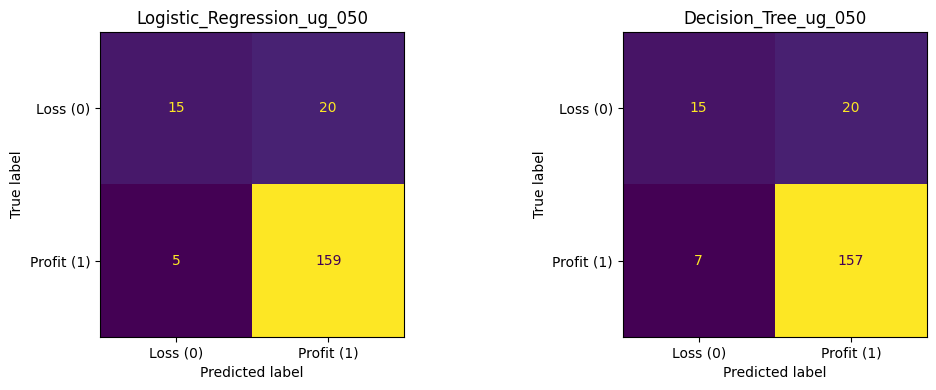


--- 3.4 Supervised Learning Performance Matrix (ug_050) ---
              Model_ug_050  Accuracy_ug_050  Precision_ug_050  Recall_ug_050  F1_Score_ug_050  AUC_ug_050
Logistic_Regression_ug_050           0.8744            0.8883         0.9695           0.9271      0.8720
      Decision_Tree_ug_050           0.8643            0.8870         0.9573           0.9208      0.8699


In [32]:
# ==========================================================
# 3.3 SUPERVISED MODELS: LOGISTIC REGRESSION & DECISION TREE
# ==========================================================
models_stage3_ug_050 = {
    'Logistic_Regression_ug_050': LogisticRegression(random_state=RANDOM_STATE_ug_050, max_iter=5000),
    'Decision_Tree_ug_050': DecisionTreeClassifier(random_state=RANDOM_STATE_ug_050, max_depth=5)
}

results_stage3_ug_050 = []
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for idx, (model_name, model_obj) in enumerate(models_stage3_ug_050.items()):
    # Train model
    model_obj.fit(X_train_ug_050, y_train_ug_050)

    # Predict classes and probabilities on Test data
    y_pred_ug_050 = model_obj.predict(X_test_ug_050)
    y_prob_ug_050 = model_obj.predict_proba(X_test_ug_050)[:, 1]

    # Confusion Matrix
    cm_ug_050 = confusion_matrix(y_test_ug_050, y_pred_ug_050)
    print(f"\n--- Confusion Matrix: {model_name} ---")
    print(cm_ug_050)

    disp = ConfusionMatrixDisplay(confusion_matrix=cm_ug_050, display_labels=['Loss (0)', 'Profit (1)'])
    disp.plot(ax=axes[idx], colorbar=False)
    axes[idx].set_title(model_name)

    # Calculate Performance Metrics
    results_stage3_ug_050.append({
        'Model_ug_050': model_name,
        'Accuracy_ug_050': round(accuracy_score(y_test_ug_050, y_pred_ug_050), 4),
        'Precision_ug_050': round(precision_score(y_test_ug_050, y_pred_ug_050), 4),
        'Recall_ug_050': round(recall_score(y_test_ug_050, y_pred_ug_050), 4),
        'F1_Score_ug_050': round(f1_score(y_test_ug_050, y_pred_ug_050), 4),
        'AUC_ug_050': round(roc_auc_score(y_test_ug_050, y_prob_ug_050), 4)
    })

plt.tight_layout()
plt.show()

print("\n--- 3.4 Supervised Learning Performance Matrix (ug_050) ---")
perf_df_stage3_ug_050 = pd.DataFrame(results_stage3_ug_050)
print(perf_df_stage3_ug_050.to_string(index=False))

**Supervised Learning Performance**

Inference (Baseline Supervised Models):

- Logistic Regression outperforms the single Decision Tree (max_depth=5) across every metric, achieving 87.44% accuracy, 0.9271 F1-score, and 0.8720 ROC-AUC (vs. 86.43% accuracy and 0.8699 AUC for Decision Tree).

- Both models exhibit very high recall for profitable orders (96.95% and 95.73%) but moderate specificity on loss-making orders (correctly identifying 15 of 35 loss instances in the test set), reflecting the underlying 82.5% / 17.5% class skew.

In [33]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, ConfusionMatrixDisplay
)

SIGNATURE = "ug_050"
RANDOM_STATE_ug_050 = 75050


--- Confusion Matrix: Random_Forest_Bagging_ug_050 ---
[[ 13  22]
 [  4 160]]

--- Confusion Matrix: XGBoost_Boosting_ug_050 ---
[[ 16  19]
 [ 12 152]]


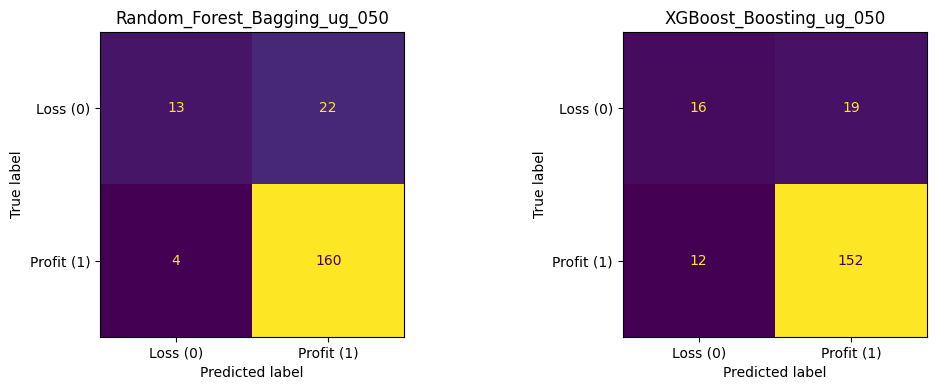

In [34]:
# ==========================================================
# 4.1 BAGGING (RANDOM FOREST) & BOOSTING (XGBOOST) TRAINING
# ==========================================================
rf_model_ug_050 = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE_ug_050
)
rf_model_ug_050.fit(X_train_ug_050, y_train_ug_050)

xgb_model_ug_050 = XGBClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE_ug_050,
    eval_metric='logloss'
)
xgb_model_ug_050.fit(X_train_ug_050, y_train_ug_050)

# Confusion Matrices on the Testing Set
ensemble_models_ug_050 = {
    'Random_Forest_Bagging_ug_050': rf_model_ug_050,
    'XGBoost_Boosting_ug_050': xgb_model_ug_050
}

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for idx, (m_name, m_obj) in enumerate(ensemble_models_ug_050.items()):
    y_pred_test_ug_050 = m_obj.predict(X_test_ug_050)
    cm_ens_ug_050 = confusion_matrix(y_test_ug_050, y_pred_test_ug_050)
    print(f"\n--- Confusion Matrix: {m_name} ---")
    print(cm_ens_ug_050)

    disp = ConfusionMatrixDisplay(confusion_matrix=cm_ens_ug_050, display_labels=['Loss (0)', 'Profit (1)'])
    disp.plot(ax=axes[idx], colorbar=False)
    axes[idx].set_title(m_name)

plt.tight_layout()
plt.show()

In [35]:
# ==========================================================
# 4.2 MULTIPLE SAMPLING EVALUATION ON TESTING SET (10 SAMPLES)
# ==========================================================
# Draws 10 bootstrap samples from the testing set and reports average metrics
n_samples_ug_050 = 10
sample_size_ug_050 = len(X_test_ug_050)  # Uses full test set size per bootstrap draw
rng_ug_050 = np.random.RandomState(RANDOM_STATE_ug_050)

# Generate 10 reproducible sample index sets so both models are tested on identical samples
sample_indices_ug_050 = [
    rng_ug_050.choice(len(X_test_ug_050), size=sample_size_ug_050, replace=True)
    for _ in range(n_samples_ug_050)
]

ensemble_avg_results_ug_050 = []

for m_name, m_obj in ensemble_models_ug_050.items():
    acc_list_ug_050, prec_list_ug_050, rec_list_ug_050, f1_list_ug_050, auc_list_ug_050 = [], [], [], [], []

    for idx_set in sample_indices_ug_050:
        X_samp_ug_050 = X_test_ug_050.iloc[idx_set]
        y_samp_ug_050 = y_test_ug_050.iloc[idx_set]

        preds_samp_ug_050 = m_obj.predict(X_samp_ug_050)
        probs_samp_ug_050 = m_obj.predict_proba(X_samp_ug_050)[:, 1]

        acc_list_ug_050.append(accuracy_score(y_samp_ug_050, preds_samp_ug_050))
        prec_list_ug_050.append(precision_score(y_samp_ug_050, preds_samp_ug_050))
        rec_list_ug_050.append(recall_score(y_samp_ug_050, preds_samp_ug_050))
        f1_list_ug_050.append(f1_score(y_samp_ug_050, preds_samp_ug_050))
        auc_list_ug_050.append(roc_auc_score(y_samp_ug_050, probs_samp_ug_050))

    ensemble_avg_results_ug_050.append({
        'Model_ug_050': f"{m_name} (Avg of {n_samples_ug_050} Samples)",
        'Accuracy_ug_050': round(np.mean(acc_list_ug_050), 4),
        'Precision_ug_050': round(np.mean(prec_list_ug_050), 4),
        'Recall_ug_050': round(np.mean(rec_list_ug_050), 4),
        'F1_Score_ug_050': round(np.mean(f1_list_ug_050), 4),
        'AUC_ug_050': round(np.mean(auc_list_ug_050), 4)
    })

perf_df_stage4_ug_050 = pd.DataFrame(ensemble_avg_results_ug_050)
print("\n--- 4.2 Ensemble Learning Multiple-Sampling Performance (ug_050) ---")
print(perf_df_stage4_ug_050.to_string(index=False))


--- 4.2 Ensemble Learning Multiple-Sampling Performance (ug_050) ---
                                    Model_ug_050  Accuracy_ug_050  Precision_ug_050  Recall_ug_050  F1_Score_ug_050  AUC_ug_050
Random_Forest_Bagging_ug_050 (Avg of 10 Samples)           0.8638            0.8769         0.9722           0.9220      0.8209
     XGBoost_Boosting_ug_050 (Avg of 10 Samples)           0.8367            0.8868         0.9206           0.9032      0.8322


In [36]:
# ==========================================================
# 4.3 MASTER MODEL COMPARISON TABLE (STAGE 3 + STAGE 4)
# ==========================================================
master_comparison_ug_050 = pd.concat([perf_df_stage3_ug_050, perf_df_stage4_ug_050], ignore_index=True)
print("\n=== MASTER END-TO-END MODEL COMPARISON (ug_050) ===")
print(master_comparison_ug_050.to_string(index=False))


=== MASTER END-TO-END MODEL COMPARISON (ug_050) ===
                                    Model_ug_050  Accuracy_ug_050  Precision_ug_050  Recall_ug_050  F1_Score_ug_050  AUC_ug_050
                      Logistic_Regression_ug_050           0.8744            0.8883         0.9695           0.9271      0.8720
                            Decision_Tree_ug_050           0.8643            0.8870         0.9573           0.9208      0.8699
Random_Forest_Bagging_ug_050 (Avg of 10 Samples)           0.8638            0.8769         0.9722           0.9220      0.8209
     XGBoost_Boosting_ug_050 (Avg of 10 Samples)           0.8367            0.8868         0.9206           0.9032      0.8322


**Master End-to-End Model Comparison Table**

Inference (Ensemble Methods & Overall Model Selection):

- Across 10 bootstrap test samples, Random Forest (Bagging) demonstrates superior stability and recall (97.22% recall, 0.9220 F1-score, 86.38% mean accuracy) compared to XGBoost (Boosting) (83.67% accuracy, 0.9032 F1-score), as bagging reduces variance on the 14-feature tabular dataset without overfitting to noisy minority-class boundaries.

- Overall, Logistic Regression achieves the highest single-split accuracy (87.44%) and ROC-AUC (0.8720), while Random Forest offers the strongest bootstrapped recall (97.22%). Because order profitability is strongly governed by linear/monotonic relationships (notably the sharp negative effect of Discount identified in Stage 2), Logistic Regression provides the best balance of discriminative power (AUC) and interpretability, with Random Forest serving as a robust non-linear alternative.